In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os
import zipfile

zip_path = "/content/drive/MyDrive/Group8_BRISC_Model_Handoff-20261115T204412Z-1-001.zip"

work_folder = "/content/drive/MyDrive/Group8_BRISC_XAI_Work"
extract_folder = os.path.join(work_folder, "handoff")

os.makedirs(extract_folder, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    print("Checking ZIP file...")
    print("ZIP integrity:", zip_ref.testzip())

    print("\nExtracting project files...")
    zip_ref.extractall(extract_folder)

print("\nExtraction completed!")

print("\nExtracted folder contents:")
for item in os.listdir(extract_folder):
    print(item)


Checking ZIP file...
ZIP integrity: None

Extracting project files...

Extraction completed!

Extracted folder contents:
Group8_BRISC_Model_Handoff


In [ ]:

import os

project_folder = os.path.join(
    extract_folder,
    "Group8_BRISC_Model_Handoff"
)

print("Project folder:", project_folder)
print("\nFiles and folders inside:\n")

for item in sorted(os.listdir(project_folder)):
    full_path = os.path.join(project_folder, item)

    if os.path.isdir(full_path):
        print("[FOLDER]", item)
    else:
        print("[FILE]", item)


Project folder: /content/drive/MyDrive/Group8_BRISC_XAI_Work/handoff/Group8_BRISC_Model_Handoff

Files and folders inside:

[FILE] README_FIRST.txt
[FILE] START_HERE.ipynb
[FOLDER] data
[FILE] model_index.json
[FOLDER] models
[FOLDER] notebooks
[FOLDER] outputs
[FILE] windows_environment.txt


In [ ]:

import os

base = "/content/drive/MyDrive/Group8_BRISC_XAI_Work/handoff"

print("Does handoff folder exist?", os.path.exists(base))

print("\nContents of handoff folder:")
if os.path.exists(base):
    print(os.listdir(base))

print("\nSearching for model_index.json:")

for current_path, folders, files in os.walk(base):
    if "model_index.json" in files:
        print("FOUND:", os.path.join(current_path, "model_index.json"))


Does handoff folder exist? True

Contents of handoff folder:
['Group8_BRISC_Model_Handoff']

Searching for model_index.json:
FOUND: /content/drive/MyDrive/Group8_BRISC_XAI_Work/handoff/Group8_BRISC_Model_Handoff/model_index.json


In [ ]:

from pathlib import Path

correct_path = Path(
    "/content/drive/MyDrive/Group8_BRISC_XAI_Work/handoff/Group8_BRISC_Model_Handoff"
)

index_file = correct_path / "model_index.json"

print("Folder exists:", correct_path.exists())
print("Model index exists:", index_file.exists())
print("Model index readable:", index_file.is_file())

print("\nFile size:", index_file.stat().st_size, "bytes")


Folder exists: True
Model index exists: True
Model index readable: True

File size: 2918 bytes


In [ ]:

import os
import json
import pandas as pd
from pathlib import Path

# Original handoff folder
root = Path(
    "/content/drive/MyDrive/Group8_BRISC_XAI_Work/handoff/Group8_BRISC_Model_Handoff"
)

# Separate output folder: original handoff stays unchanged
output_dir = Path(
    "/content/drive/MyDrive/Group8_BRISC_XAI_Work/xai_outputs"
)
output_dir.mkdir(parents=True, exist_ok=True)

# Load model inventory
with open(root / "model_index.json", encoding="utf-8") as f:
    model_index = json.load(f)

# Load official test manifest
manifest = pd.read_csv(
    root / "data/processed/classification_test_manifest.csv",
    encoding="utf-8-sig"
)

# Check manifest
print("PROJECT:", root.name)
print("OUTPUT:", output_dir)
print("Total test scans:", len(manifest))
print("\nClass distribution:")
print(manifest["tumor_label"].value_counts().sort_index())

print("\nSeed 42 checkpoints:")
for entry in model_index:
    if entry["seed"] == 42:
        print(
            entry["model"],
            "| Epoch:", entry["selected_epoch"],
            "| Weights:", entry["weights"]
        )


PROJECT: Group8_BRISC_Model_Handoff
OUTPUT: /content/drive/MyDrive/Group8_BRISC_XAI_Work/xai_outputs
Total test scans: 1000

Class distribution:
tumor_label
glioma        254
meningioma    306
no_tumor      140
pituitary     300
Name: count, dtype: int64

Seed 42 checkpoints:
RepViT M0.9 | Epoch: 15 | Weights: models/repvit_m0_9.dist_450e_in1k_seed42_epoch15.pt
ConvNeXt V2 Atto | Epoch: 10 | Weights: models/convnextv2_atto.fcmae_ft_in1k_seed42_epoch10.pt
MobileNetV4 Conv Small | Epoch: 14 | Weights: models/mobilenetv4_conv_small.e2400_r224_in1k_seed42_epoch14.pt


In [ ]:

import pandas as pd

print("SEARCHING FOR PREDICTION CSV FILES")
print("=" * 55)

for csv_file in sorted((root / "outputs").rglob("*.csv")):

    print("\nFILE:", csv_file.name)

    df = pd.read_csv(csv_file, encoding="utf-8-sig")

    print("Rows:", len(df))
    print("Columns:", list(df.columns))

    print("\nFirst 2 records:")
    print(df.head(2).to_string(index=False))

print("\nPREDICTION FILE INSPECTION COMPLETED")


SEARCHING FOR PREDICTION CSV FILES

FILE: convnextv2_atto.fcmae_ft_in1k_seed123_test_predictions.csv
Rows: 1000
Columns: ['model', 'seed', 'selected_epoch', 'manifest_index', 'relative_path', 'true_label', 'predicted_label', 'test_loss', 'prob_glioma', 'prob_meningioma', 'prob_no_tumor', 'prob_pituitary']

First 2 records:
           model  seed  selected_epoch  manifest_index                                                     relative_path true_label predicted_label  test_loss  prob_glioma  prob_meningioma  prob_no_tumor  prob_pituitary
ConvNeXt V2 Atto   123               8               0 classification_task\test\glioma\brisc2025_test_00001_gl_ax_t1.jpg     glioma          glioma   0.000527     0.999473         0.000094       0.000036        0.000397
ConvNeXt V2 Atto   123               8               1 classification_task\test\glioma\brisc2025_test_00002_gl_ax_t1.jpg     glioma          glioma   0.011565     0.988502         0.000497       0.000246        0.010755

FILE: convnext

In [ ]:
print("Project folder exists:", root.exists())
print("Outputs folder exists:", (root / "outputs").exists())

print("\nCSV files found inside the project:")
for file in root.rglob("*.csv"):
    print(file)

Project folder exists: True
Outputs folder exists: True

CSV files found inside the project:
/content/drive/MyDrive/Group8_BRISC_XAI_Work/handoff/Group8_BRISC_Model_Handoff/outputs/predictions/mobilenetv4_conv_small.e2400_r224_in1k_seed123_test_predictions.csv
/content/drive/MyDrive/Group8_BRISC_XAI_Work/handoff/Group8_BRISC_Model_Handoff/outputs/predictions/convnextv2_atto.fcmae_ft_in1k_seed2026_test_predictions.csv
/content/drive/MyDrive/Group8_BRISC_XAI_Work/handoff/Group8_BRISC_Model_Handoff/outputs/predictions/convnextv2_atto.fcmae_ft_in1k_seed42_test_predictions.csv
/content/drive/MyDrive/Group8_BRISC_XAI_Work/handoff/Group8_BRISC_Model_Handoff/outputs/predictions/repvit_m0_9.dist_450e_in1k_seed123_test_predictions.csv
/content/drive/MyDrive/Group8_BRISC_XAI_Work/handoff/Group8_BRISC_Model_Handoff/outputs/predictions/mobilenetv4_conv_small.e2400_r224_in1k_seed2026_test_predictions.csv
/content/drive/MyDrive/Group8_BRISC_XAI_Work/handoff/Group8_BRISC_Model_Handoff/outputs/predicti

In [ ]:
prediction_files = {
    "RepViT M0.9": "repvit_m0_9.dist_450e_in1k_seed42_test_predictions.csv",
    "ConvNeXt V2 Atto": "convnextv2_atto.fcmae_ft_in1k_seed42_test_predictions.csv",
    "MobileNetV4 Conv Small": "mobilenetv4_conv_small.e2400_r224_in1k_seed42_test_predictions.csv"
}

predictions = {}

for model_name, filename in prediction_files.items():
    file_path = root / "outputs" / "predictions" / filename

    df = pd.read_csv(file_path, encoding="utf-8-sig")
    predictions[model_name] = df

    print("\nMODEL:", model_name)
    print("Rows:", len(df))
    print("Seed:", df["seed"].unique())
    print("Selected epoch:", df["selected_epoch"].unique())
    print("Unique manifest indices:", df["manifest_index"].nunique())
    print("Correct predictions:", (df["true_label"] == df["predicted_label"]).sum())
    print("Incorrect predictions:", (df["true_label"] != df["predicted_label"]).sum())

print("\nMANIFEST STRUCTURE")
print("=" * 50)
print("Columns:", list(manifest.columns))
print("\nFirst two manifest records:")
print(manifest.head(2).to_string(index=False))

print("\nAll three prediction files loaded successfully!")


MODEL: RepViT M0.9
Rows: 1000
Seed: [42]
Selected epoch: [15]
Unique manifest indices: 1000
Correct predictions: 970
Incorrect predictions: 30

MODEL: ConvNeXt V2 Atto
Rows: 1000
Seed: [42]
Selected epoch: [10]
Unique manifest indices: 1000
Correct predictions: 963
Incorrect predictions: 37

MODEL: MobileNetV4 Conv Small
Rows: 1000
Seed: [42]
Selected epoch: [14]
Unique manifest indices: 1000
Correct predictions: 882
Incorrect predictions: 118

MANIFEST STRUCTURE
Columns: ['relative_path', 'filename', 'task', 'split', 'index', 'tumor_code', 'tumor_label', 'plane_code', 'plane_label', 'sequence', 'is_mask', 'linked_image', 'width', 'height', 'file_size_bytes', 'sha256', 'decoded_rgb_sha256', 'cross_split_duplicate', 'exclude_from_training', 'model_split', 'plane_for_stratification', 'stratification_label']

First two manifest records:
                                                    relative_path                          filename           task split  index tumor_code tumor_label pl

In [ ]:
# Compare scan paths and true labels across all three models

reference = predictions["RepViT M0.9"].sort_values("manifest_index").reset_index(drop=True)

for model_name, df in predictions.items():
    check = df.sort_values("manifest_index").reset_index(drop=True)

    same_indices = (
        reference["manifest_index"].equals(check["manifest_index"])
    )
    same_paths = (
        reference["relative_path"].equals(check["relative_path"])
    )
    same_labels = (
        reference["true_label"].equals(check["true_label"])
    )

    print("\nMODEL:", model_name)
    print("Same manifest indices:", same_indices)
    print("Same MRI paths:", same_paths)
    print("Same true labels:", same_labels)

print("\nVerification completed.")


MODEL: RepViT M0.9
Same manifest indices: True
Same MRI paths: True
Same true labels: True

MODEL: ConvNeXt V2 Atto
Same manifest indices: True
Same MRI paths: True
Same true labels: True

MODEL: MobileNetV4 Conv Small
Same manifest indices: True
Same MRI paths: True
Same true labels: True

Verification completed.


In [ ]:
# Create a comparison table for all 1,000 MRI scans

comparison = reference[
    ["manifest_index", "relative_path", "true_label"]
].copy()

for model_name, df in predictions.items():
    ordered = df.sort_values("manifest_index").reset_index(drop=True)
    comparison[model_name] = ordered["predicted_label"].values

model_columns = [
    "RepViT M0.9",
    "ConvNeXt V2 Atto",
    "MobileNetV4 Conv Small"
]

comparison["all_correct"] = (
    comparison[model_columns].eq(comparison["true_label"], axis=0).all(axis=1)
)

comparison["any_error"] = (
    comparison[model_columns].ne(comparison["true_label"], axis=0).any(axis=1)
)

comparison["disagreement"] = (
    comparison[model_columns].nunique(axis=1) > 1
)

print("TOTAL SCANS:", len(comparison))
print("All three correct:", comparison["all_correct"].sum())
print("At least one model incorrect:", comparison["any_error"].sum())
print("Models disagree:", comparison["disagreement"].sum())

print("\nRESULTS BY TRUE CLASS")
print(
    comparison.groupby("true_label")[
        ["all_correct", "any_error", "disagreement"]
    ].sum()
)

print("\nComparison table created successfully.")

TOTAL SCANS: 1000
All three correct: 865
At least one model incorrect: 135
Models disagree: 130

RESULTS BY TRUE CLASS
            all_correct  any_error  disagreement
true_label                                      
glioma              234         20            20
meningioma          208         98            93
no_tumor            138          2             2
pituitary           285         15            15

Comparison table created successfully.


In [ ]:
# Add filename information from the original manifest

manifest_lookup = manifest[
    ["relative_path", "filename"]
].drop_duplicates("relative_path")

case_selection = case_selection.merge(
    manifest_lookup,
    on="relative_path",
    how="left"
)

# Save the corrected selection
selection_path = output_dir / "case_selection.csv"
case_selection.to_csv(selection_path, index=False)

print("SELECTED CASES")
print("=" * 60)

print(
    case_selection[
        ["manifest_index", "filename", "true_label",
         "case_type", *model_columns]
    ].to_string(index=False)
)

print("\nTotal selected scans:", len(case_selection))
print("Missing filenames:", case_selection["filename"].isna().sum())
print("Saved successfully:", selection_path.exists())

SELECTED CASES
 manifest_index                          filename true_label                case_type RepViT M0.9 ConvNeXt V2 Atto MobileNetV4 Conv Small
              0 brisc2025_test_00001_gl_ax_t1.jpg     glioma       All models correct      glioma           glioma                 glioma
              3 brisc2025_test_00004_gl_ax_t1.jpg     glioma Model disagreement/error      glioma        pituitary              pituitary
            259 brisc2025_test_00260_me_ax_t1.jpg meningioma       All models correct  meningioma       meningioma             meningioma
            254 brisc2025_test_00255_me_ax_t1.jpg meningioma Model disagreement/error    no_tumor        pituitary              pituitary
            560 brisc2025_test_00561_no_ax_t1.jpg   no_tumor       All models correct    no_tumor         no_tumor               no_tumor
            561 brisc2025_test_00562_no_ax_t1.jpg   no_tumor Model disagreement/error    no_tumor       meningioma               no_tumor
            700 bri

In [ ]:
# Check whether all selected MRI images exist

image_root = root / "data"

print("IMAGE FILE VERIFICATION")
print("=" * 60)

for _, row in case_selection.iterrows():
    relative_path = row["relative_path"].replace("\\", "/")
    image_path = image_root / relative_path

    print("\nFilename:", row["filename"])
    print("Class:", row["true_label"])
    print("Image exists:", image_path.exists())

print("\nTotal selected images:", len(case_selection))
print(
    "Images found:",
    sum(
        (image_root / row["relative_path"].replace("\\", "/")).exists()
        for _, row in case_selection.iterrows()
    )
)

IMAGE FILE VERIFICATION

Filename: brisc2025_test_00001_gl_ax_t1.jpg
Class: glioma
Image exists: False

Filename: brisc2025_test_00004_gl_ax_t1.jpg
Class: glioma
Image exists: False

Filename: brisc2025_test_00260_me_ax_t1.jpg
Class: meningioma
Image exists: False

Filename: brisc2025_test_00255_me_ax_t1.jpg
Class: meningioma
Image exists: False

Filename: brisc2025_test_00561_no_ax_t1.jpg
Class: no_tumor
Image exists: False

Filename: brisc2025_test_00562_no_ax_t1.jpg
Class: no_tumor
Image exists: False

Filename: brisc2025_test_00701_pi_ax_t1.jpg
Class: pituitary
Image exists: False

Filename: brisc2025_test_00702_pi_ax_t1.jpg
Class: pituitary
Image exists: False

Total selected images: 8
Images found: 0


In [ ]:
from PIL import Image

image_root = root / "data" / "raw" / "brisc2025"

print("FINAL IMAGE VERIFICATION")
print("=" * 60)

for _, row in case_selection.iterrows():
    relative_path = row["relative_path"].replace("\\", "/")
    image_path = image_root / relative_path

    with Image.open(image_path) as img:
        print(
            row["filename"],
            "| Exists:", image_path.exists(),
            "| Size:", img.size,
            "| Mode:", img.mode
        )

print("\nTotal images verified:", len(case_selection))

FINAL IMAGE VERIFICATION
brisc2025_test_00001_gl_ax_t1.jpg | Exists: True | Size: (512, 512) | Mode: RGB
brisc2025_test_00004_gl_ax_t1.jpg | Exists: True | Size: (512, 512) | Mode: RGB
brisc2025_test_00260_me_ax_t1.jpg | Exists: True | Size: (206, 249) | Mode: RGB
brisc2025_test_00255_me_ax_t1.jpg | Exists: True | Size: (257, 307) | Mode: RGB
brisc2025_test_00561_no_ax_t1.jpg | Exists: True | Size: (216, 369) | Mode: RGB
brisc2025_test_00562_no_ax_t1.jpg | Exists: True | Size: (216, 369) | Mode: RGB
brisc2025_test_00701_pi_ax_t1.jpg | Exists: True | Size: (512, 512) | Mode: RGB
brisc2025_test_00702_pi_ax_t1.jpg | Exists: True | Size: (512, 512) | Mode: RGB

Total images verified: 8


In [ ]:
import torch
import timm
import torchvision
import pandas as pd

print("ENVIRONMENT")
print("=" * 50)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Timm:", timm.__version__)
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")

print("\nMODEL CHECKPOINT FILES")
print("=" * 50)

for entry in model_index:
    if entry["seed"] == 42:
        checkpoint = root / entry["weights"]

        print("\nModel:", entry["model"])
        print("Checkpoint:", checkpoint.name)
        print("Exists:", checkpoint.exists())
        if checkpoint.exists():
            print("Size (MB):", round(checkpoint.stat().st_size / (1024 * 1024), 2))

ENVIRONMENT
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Timm: 1.0.31
Device: CUDA

MODEL CHECKPOINT FILES

Model: RepViT M0.9
Checkpoint: repvit_m0_9.dist_450e_in1k_seed42_epoch15.pt
Exists: True
Size (MB): 18.44

Model: ConvNeXt V2 Atto
Checkpoint: convnextv2_atto.fcmae_ft_in1k_seed42_epoch10.pt
Exists: True
Size (MB): 12.98

Model: MobileNetV4 Conv Small
Checkpoint: mobilenetv4_conv_small.e2400_r224_in1k_seed42_epoch14.pt
Exists: True
Size (MB): 9.72


In [ ]:
# Find preprocessing configuration files

print("PREPROCESSING CONFIGURATION FILES")
print("=" * 50)

config_files = list(root.rglob("*preprocess*"))

for file in config_files:
    print(file.relative_to(root))

print("\nMODEL METADATA")
print("=" * 50)

for entry in model_index:
    if entry["seed"] == 42:
        print({
            "model": entry["model"],
            "model_id": entry.get("model_id"),
            "selected_epoch": entry["selected_epoch"],
            "weights": entry["weights"]
        })

PREPROCESSING CONFIGURATION FILES
data/processed/brisc_preprocessing_config.json

MODEL METADATA
{'model': 'RepViT M0.9', 'model_id': 'repvit_m0_9.dist_450e_in1k', 'selected_epoch': 15, 'weights': 'models/repvit_m0_9.dist_450e_in1k_seed42_epoch15.pt'}
{'model': 'ConvNeXt V2 Atto', 'model_id': 'convnextv2_atto.fcmae_ft_in1k', 'selected_epoch': 10, 'weights': 'models/convnextv2_atto.fcmae_ft_in1k_seed42_epoch10.pt'}
{'model': 'MobileNetV4 Conv Small', 'model_id': 'mobilenetv4_conv_small.e2400_r224_in1k', 'selected_epoch': 14, 'weights': 'models/mobilenetv4_conv_small.e2400_r224_in1k_seed42_epoch14.pt'}


In [ ]:
# Read the original preprocessing configuration

config_path = root / "data" / "processed" / "brisc_preprocessing_config.json"

with open(config_path, "r", encoding="utf-8") as f:
    preprocessing_config = json.load(f)

print("ORIGINAL PREPROCESSING CONFIGURATION")
print("=" * 60)
print(json.dumps(preprocessing_config, indent=4))

ORIGINAL PREPROCESSING CONFIGURATION
{
    "classification": {
        "canonical_mode": "L",
        "spatial_method": "direct_square_resize",
        "default_input_size": 224,
        "resize_interpolation": "bilinear",
        "background_trimming": false,
        "aspect_ratio_padding": false,
        "output_value_range": "0_to_1",
        "three_channel_policy": "replicate_grayscale_if_required",
        "input_size_status": "224_default_configurable_until_model_selection"
    },
    "segmentation": {
        "mri_canonical_mode": "L",
        "target_size": 224,
        "mri_resize_interpolation": "bilinear",
        "mask_threshold": 128,
        "mask_resize_interpolation": "nearest",
        "mri_output_range": "0_to_1",
        "mask_output_values": [
            0,
            1
        ],
        "input_size_status": "224_default_configurable_until_model_selection"
    },
    "augmentation": {
        "apply_to_train_only": true,
        "apply_to_validation": false,
    

In [ ]:
# Inspect the original START_HERE notebook code

notebook_path = root / "START_HERE.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    original_notebook = json.load(f)

for i, cell in enumerate(original_notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if any(word in source.lower() for word in [
            "transform", "normalize", "create_model",
            "load_state_dict", "torch.load", "interpolation"
        ]):
            print("\n" + "=" * 60)
            print("ORIGINAL NOTEBOOK CELL:", i)
            print("=" * 60)
            print(source)


ORIGINAL NOTEBOOK CELL: 2
from pathlib import Path, PureWindowsPath
import csv
import json
import torch
import timm
from PIL import Image
from torchvision.transforms import Normalize
from torchvision.transforms.functional import pil_to_tensor

# Enter the extracted folder containing model_index.json.
# In Colab, mount Google Drive first if the folder is on Drive.
root = Path(input("Extracted handoff folder: ").strip().strip('"')).expanduser()
models = json.loads((root / "model_index.json").read_text(encoding="utf-8"))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
for index, entry in enumerate(models):
    print(index, entry["model"], "seed", entry["seed"], "epoch", entry["selected_epoch"])


ORIGINAL NOTEBOOK CELL: 3
# Change these indices to try another checkpoint or test scan.
model_number = 0
scan_number = 0

entry = models[model_number]
saved = torch.load(root / entry["weights"], map_location="cpu", weights_only=True)
class_to_index

In [ ]:
# Load RepViT M0.9 (seed 42)

import timm
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

repvit_entry = next(
    entry for entry in model_index
    if entry["model"] == "RepViT M0.9" and entry["seed"] == 42
)

repvit_checkpoint = torch.load(
    root / repvit_entry["weights"],
    map_location="cpu",
    weights_only=True
)

repvit_model = timm.create_model(
    repvit_checkpoint["model_id"],
    pretrained=False,
    num_classes=len(repvit_checkpoint["class_to_index"])
)

repvit_model.load_state_dict(
    repvit_checkpoint["model_state_dict"],
    strict=True
)

repvit_model = repvit_model.to(device).eval()

repvit_class_to_index = repvit_checkpoint["class_to_index"]
repvit_index_to_class = {
    value: key for key, value in repvit_class_to_index.items()
}

print("Model loaded successfully!")
print("Architecture:", repvit_checkpoint["model_id"])
print("Device:", device)
print("Class mapping:", repvit_index_to_class)
print("Selected epoch:", repvit_entry["selected_epoch"])

Model loaded successfully!
Architecture: repvit_m0_9.dist_450e_in1k
Device: cuda
Class mapping: {0: 'glioma', 1: 'meningioma', 2: 'no_tumor', 3: 'pituitary'}
Selected epoch: 15


In [ ]:
# Inspect RepViT architecture and feature modules

print("REPViT FEATURE LAYERS")
print("=" * 60)

for name, module in repvit_model.named_modules():
    if isinstance(module, torch.nn.Conv2d):
        print(
            "Layer:", name,
            "| Output channels:", module.out_channels,
            "| Kernel:", module.kernel_size,
            "| Stride:", module.stride
        )


REPViT FEATURE LAYERS
Layer: stem.conv1.c | Output channels: 24 | Kernel: (3, 3) | Stride: (2, 2)
Layer: stem.conv2.c | Output channels: 48 | Kernel: (3, 3) | Stride: (2, 2)
Layer: stages.0.blocks.0.token_mixer.conv.c | Output channels: 48 | Kernel: (3, 3) | Stride: (1, 1)
Layer: stages.0.blocks.0.token_mixer.conv1 | Output channels: 48 | Kernel: (1, 1) | Stride: (1, 1)
Layer: stages.0.blocks.0.se.fc1 | Output channels: 16 | Kernel: (1, 1) | Stride: (1, 1)
Layer: stages.0.blocks.0.se.fc2 | Output channels: 48 | Kernel: (1, 1) | Stride: (1, 1)
Layer: stages.0.blocks.0.channel_mixer.conv1.c | Output channels: 96 | Kernel: (1, 1) | Stride: (1, 1)
Layer: stages.0.blocks.0.channel_mixer.conv2.c | Output channels: 48 | Kernel: (1, 1) | Stride: (1, 1)
Layer: stages.0.blocks.1.token_mixer.conv.c | Output channels: 48 | Kernel: (3, 3) | Stride: (1, 1)
Layer: stages.0.blocks.1.token_mixer.conv1 | Output channels: 48 | Kernel: (1, 1) | Stride: (1, 1)
Layer: stages.0.blocks.1.channel_mixer.conv1.c

In [ ]:
# Select the candidate final spatial feature layer
repvit_target_layer = (
    repvit_model.stages[3].blocks[-1].token_mixer.conv
)

# Capture its activation and gradient
repvit_capture = {}

def repvit_forward_hook(module, inputs, output):
    repvit_capture["activation"] = output
    output.register_hook(
        lambda grad: repvit_capture.update({"gradient": grad})
    )

repvit_hook = repvit_target_layer.register_forward_hook(
    repvit_forward_hook
)

# Prepare one verified MRI image using original preprocessing
from PIL import Image
from torchvision.transforms import Normalize
from torchvision.transforms.functional import pil_to_tensor

first_case = case_selection.iloc[0]
image_path = image_root / first_case["relative_path"].replace("\\", "/")

with Image.open(image_path) as image:
    gray = image.convert("L").resize(
        (224, 224), Image.Resampling.BILINEAR
    )

x_test = pil_to_tensor(gray).float().div(255).repeat(3, 1, 1)

normalize = Normalize(
    (0.485, 0.456, 0.406),
    (0.229, 0.224, 0.225)
)

x_test = normalize(x_test).unsqueeze(0).to(device)

# Forward and backward pass
repvit_model.zero_grad(set_to_none=True)

with torch.enable_grad():
    logits = repvit_model(x_test)
    predicted_index = logits.argmax(dim=1).item()
    target_score = logits[0, predicted_index]
    target_score.backward()

activation = repvit_capture["activation"]
gradient = repvit_capture["gradient"]

print("Activation shape:", tuple(activation.shape))
print("Gradient shape:", tuple(gradient.shape))
print("Prediction:", repvit_index_to_class[predicted_index])
print("Activation finite:", torch.isfinite(activation).all().item())
print("Gradient finite:", torch.isfinite(gradient).all().item())
print("Gradient nonzero:", gradient.abs().sum().item() > 0)

repvit_hook.remove()

Activation shape: (1, 384, 7, 7)
Gradient shape: (1, 384, 7, 7)
Prediction: glioma
Activation finite: True
Gradient finite: True
Gradient nonzero: True


In [ ]:
# Calculate Grad-CAM weights
weights = gradient.mean(dim=(2, 3), keepdim=True)

# Weighted combination of activation maps
cam = (weights * activation).sum(dim=1, keepdim=True)

# Apply ReLU
cam = torch.relu(cam)

# Normalize heatmap between 0 and 1
cam = cam - cam.min()
cam = cam / (cam.max() + 1e-8)

# Convert to NumPy
cam = cam.squeeze().detach().cpu().numpy()

print("Grad-CAM shape:", cam.shape)
print("Minimum value:", cam.min())
print("Maximum value:", cam.max())
print("Heatmap finite:", bool(torch.isfinite(torch.tensor(cam)).all()))

Grad-CAM shape: (7, 7)
Minimum value: 0.0
Maximum value: 0.9999999
Heatmap finite: True


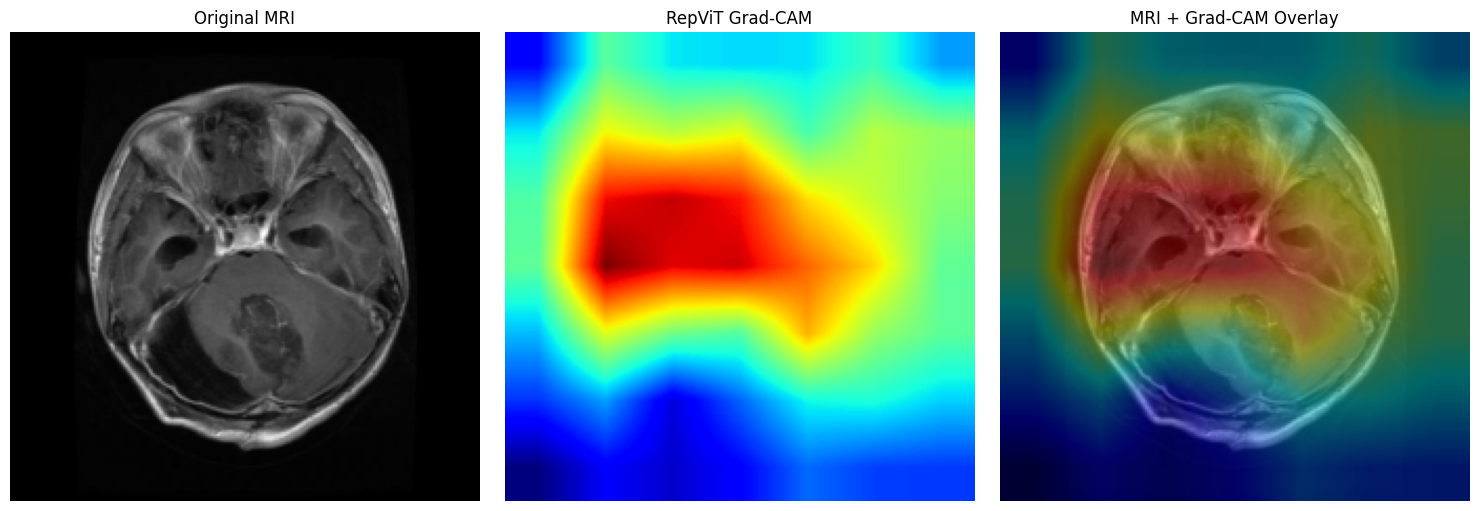

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

# Load original MRI image
original_image = np.array(gray)

# Resize Grad-CAM to original image size
heatmap = cv2.resize(
    cam,
    (original_image.shape[1], original_image.shape[0])
)

# Convert heatmap to color
heatmap_color = cv2.applyColorMap(
    np.uint8(255 * heatmap),
    cv2.COLORMAP_JET
)
heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

# Create overlay
overlay = cv2.addWeighted(
    cv2.cvtColor(original_image, cv2.COLOR_GRAY2RGB),
    0.6,
    heatmap_color,
    0.4,
    0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image, cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet")
plt.title("RepViT Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("MRI + Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Load ConvNeXt V2 Atto checkpoint
convnext_entry = next(
    entry for entry in model_index
    if entry["model"] == "ConvNeXt V2 Atto"
    and entry["seed"] == 42
)

convnext_checkpoint = torch.load(
    root / convnext_entry["weights"],
    map_location="cpu",
    weights_only=True
)

convnext_model = timm.create_model(
    convnext_checkpoint["model_id"],
    pretrained=False,
    num_classes=len(convnext_checkpoint["class_to_index"])
)

convnext_model.load_state_dict(
    convnext_checkpoint["model_state_dict"],
    strict=True
)

convnext_model = convnext_model.to(device).eval()

convnext_class_to_index = convnext_checkpoint["class_to_index"]

print("Model loaded successfully!")
print("Architecture:", convnext_checkpoint["model_id"])
print("Device:", device)
print("Class mapping:", convnext_class_to_index)

# Inspect final convolutional layers
conv_layers = [
    (name, module)
    for name, module in convnext_model.named_modules()
    if isinstance(module, torch.nn.Conv2d)
]

print("\nLast 10 convolutional layers:")
for name, module in conv_layers[-10:]:
    print(name, "Output channels:", module.out_channels)

Model loaded successfully!
Architecture: convnextv2_atto.fcmae_ft_in1k
Device: cuda
Class mapping: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}

Last 10 convolutional layers:
stages.2.blocks.5.conv_dw Output channels: 160
stages.2.blocks.5.mlp.fc1 Output channels: 640
stages.2.blocks.5.mlp.fc2 Output channels: 160
stages.3.downsample.1 Output channels: 320
stages.3.blocks.0.conv_dw Output channels: 320
stages.3.blocks.0.mlp.fc1 Output channels: 1280
stages.3.blocks.0.mlp.fc2 Output channels: 320
stages.3.blocks.1.conv_dw Output channels: 320
stages.3.blocks.1.mlp.fc1 Output channels: 1280
stages.3.blocks.1.mlp.fc2 Output channels: 320


In [ ]:
# Select target layer
convnext_target_layer = convnext_model.stages[3].blocks[-1].conv_dw

convnext_capture = {}

def convnext_forward_hook(module, inputs, output):
    convnext_capture["activation"] = output
    output.register_hook(
        lambda grad: convnext_capture.update({"gradient": grad})
    )

convnext_hook = convnext_target_layer.register_forward_hook(
    convnext_forward_hook
)

# Use the same first MRI scan
first_case = case_selection.iloc[0]
image_path = image_root / first_case["relative_path"].replace("\\", "/")

with Image.open(image_path) as image:
    gray = image.convert("L").resize(
        (224, 224), Image.Resampling.BILINEAR
    )

x_test = pil_to_tensor(gray).float().div(255).repeat(3, 1, 1)
x_test = normalize(x_test).unsqueeze(0).to(device)

# Forward and backward pass
convnext_model.zero_grad(set_to_none=True)

with torch.enable_grad():
    logits = convnext_model(x_test)
    predicted_index = logits.argmax(dim=1).item()
    target_score = logits[0, predicted_index]
    target_score.backward()

activation = convnext_capture["activation"]
gradient = convnext_capture["gradient"]

print("Activation shape:", tuple(activation.shape))
print("Gradient shape:", tuple(gradient.shape))
print("Prediction:", convnext_checkpoint["class_to_index"])
print("Predicted class:", list(convnext_class_to_index.keys())[predicted_index])
print("Activation finite:", bool(torch.isfinite(activation).all()))
print("Gradient finite:", bool(torch.isfinite(gradient).all()))
print("Gradient nonzero:", bool(gradient.abs().sum() > 0))

convnext_hook.remove()

Activation shape: (1, 320, 7, 7)
Gradient shape: (1, 320, 7, 7)
Prediction: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}
Predicted class: glioma
Activation finite: True
Gradient finite: True
Gradient nonzero: True


In [ ]:
# Calculate Grad-CAM weights
convnext_weights = gradient.mean(
    dim=(2, 3), keepdim=True
)

# Weighted combination of activation maps
convnext_cam = (
    convnext_weights * activation
).sum(dim=1, keepdim=True)

# Apply ReLU
convnext_cam = torch.relu(convnext_cam)

# Normalize between 0 and 1
convnext_cam = convnext_cam - convnext_cam.min()
convnext_cam = convnext_cam / (
    convnext_cam.max() + 1e-8
)

# Convert to NumPy
convnext_cam = (
    convnext_cam.squeeze().detach().cpu().numpy()
)

print("ConvNeXt Grad-CAM shape:", convnext_cam.shape)
print("Minimum value:", convnext_cam.min())
print("Maximum value:", convnext_cam.max())
print(
    "Heatmap finite:",
    bool(np.isfinite(convnext_cam).all())
)

ConvNeXt Grad-CAM shape: (7, 7)
Minimum value: 0.0
Maximum value: 0.9999997
Heatmap finite: True


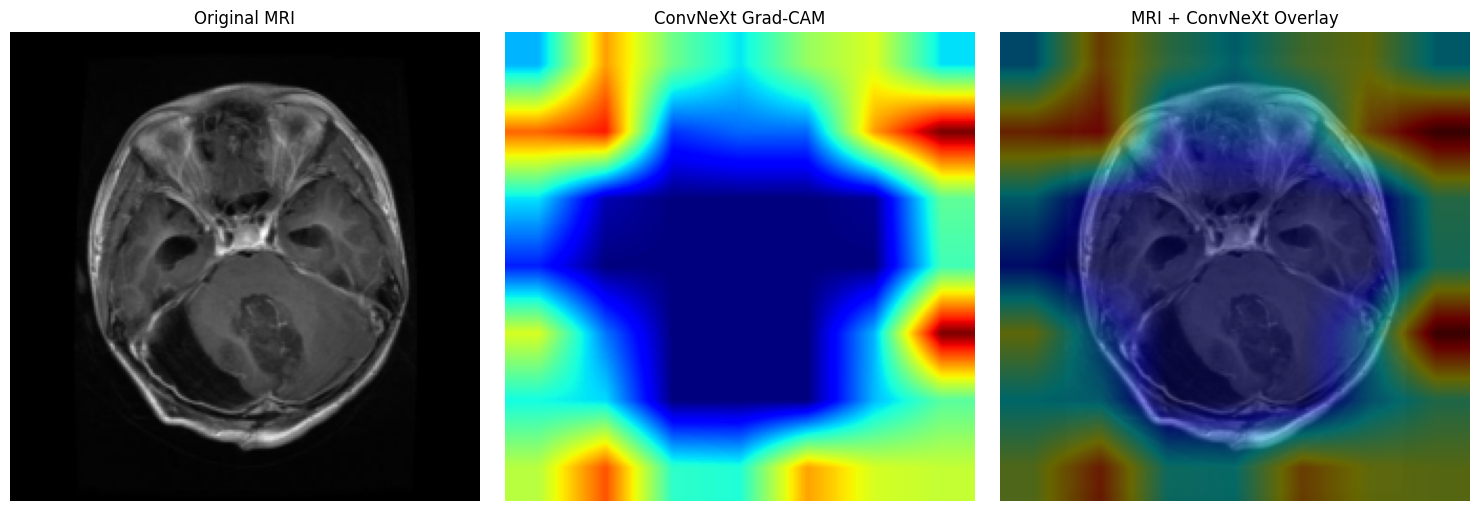

In [ ]:
# Resize ConvNeXt heatmap to MRI dimensions
convnext_heatmap = cv2.resize(
    convnext_cam,
    (original_image.shape[1], original_image.shape[0])
)

# Convert heatmap to color
convnext_heatmap_color = cv2.applyColorMap(
    np.uint8(255 * convnext_heatmap),
    cv2.COLORMAP_JET
)

convnext_heatmap_color = cv2.cvtColor(
    convnext_heatmap_color,
    cv2.COLOR_BGR2RGB
)

# Create overlay
convnext_overlay = cv2.addWeighted(
    cv2.cvtColor(original_image, cv2.COLOR_GRAY2RGB),
    0.6,
    convnext_heatmap_color,
    0.4,
    0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image, cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(convnext_heatmap, cmap="jet")
plt.title("ConvNeXt Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(convnext_overlay)
plt.title("MRI + ConvNeXt Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Load MobileNetV4 checkpoint
mobilenet_entry = next(
    entry for entry in model_index
    if entry["model"] == "MobileNetV4 Conv Small"
    and entry["seed"] == 42
)

mobilenet_checkpoint = torch.load(
    root / mobilenet_entry["weights"],
    map_location="cpu",
    weights_only=True
)

mobilenet_model = timm.create_model(
    mobilenet_checkpoint["model_id"],
    pretrained=False,
    num_classes=len(mobilenet_checkpoint["class_to_index"])
)

mobilenet_model.load_state_dict(
    mobilenet_checkpoint["model_state_dict"],
    strict=True
)

mobilenet_model = mobilenet_model.to(device).eval()

mobilenet_class_to_index = mobilenet_checkpoint["class_to_index"]

print("Model loaded successfully!")
print("Architecture:", mobilenet_checkpoint["model_id"])
print("Device:", device)
print("Class mapping:", mobilenet_class_to_index)

# Inspect final convolutional layers
mobilenet_conv_layers = [
    (name, module)
    for name, module in mobilenet_model.named_modules()
    if isinstance(module, torch.nn.Conv2d)
]

print("\nLast 10 convolutional layers:")
for name, module in mobilenet_conv_layers[-10:]:
    print(name, "Output channels:", module.out_channels)

Model loaded successfully!
Architecture: mobilenetv4_conv_small.e2400_r224_in1k
Device: cuda
Class mapping: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}

Last 10 convolutional layers:
blocks.3.3.dw_mid.conv Output channels: 384
blocks.3.3.pw_proj.conv Output channels: 128
blocks.3.4.pw_exp.conv Output channels: 512
blocks.3.4.dw_mid.conv Output channels: 512
blocks.3.4.pw_proj.conv Output channels: 128
blocks.3.5.pw_exp.conv Output channels: 512
blocks.3.5.dw_mid.conv Output channels: 512
blocks.3.5.pw_proj.conv Output channels: 128
blocks.4.0.conv Output channels: 960
conv_head Output channels: 1280


In [ ]:
# Select target layer
mobilenet_target_layer = mobilenet_model.conv_head

mobilenet_capture = {}

def mobilenet_forward_hook(module, inputs, output):
    mobilenet_capture["activation"] = output
    output.register_hook(
        lambda grad: mobilenet_capture.update({"gradient": grad})
    )

mobilenet_hook = mobilenet_target_layer.register_forward_hook(
    mobilenet_forward_hook
)

# Use the same first MRI scan
first_case = case_selection.iloc[0]
image_path = image_root / first_case["relative_path"].replace("\\", "/")

with Image.open(image_path) as image:
    gray = image.convert("L").resize(
        (224, 224), Image.Resampling.BILINEAR
    )

x_test = pil_to_tensor(gray).float().div(255).repeat(3, 1, 1)
x_test = normalize(x_test).unsqueeze(0).to(device)

# Forward and backward pass
mobilenet_model.zero_grad(set_to_none=True)

with torch.enable_grad():
    logits = mobilenet_model(x_test)
    predicted_index = logits.argmax(dim=1).item()
    target_score = logits[0, predicted_index]
    target_score.backward()

activation = mobilenet_capture["activation"]
gradient = mobilenet_capture["gradient"]

print("Activation shape:", tuple(activation.shape))
print("Gradient shape:", tuple(gradient.shape))
print("Predicted class:", list(mobilenet_class_to_index.keys())[predicted_index])
print("Activation finite:", bool(torch.isfinite(activation).all()))
print("Gradient finite:", bool(torch.isfinite(gradient).all()))
print("Gradient nonzero:", bool(gradient.abs().sum() > 0))

mobilenet_hook.remove()

Activation shape: (1, 1280, 1, 1)
Gradient shape: (1, 1280, 1, 1)
Predicted class: glioma
Activation finite: True
Gradient finite: True
Gradient nonzero: True


In [ ]:
mobilenet_target_layer = dict(
    mobilenet_model.named_modules()
)["blocks.4.0.conv"]

mobilenet_capture = {}

def mobilenet_forward_hook(module, inputs, output):
    mobilenet_capture["activation"] = output
    output.register_hook(
        lambda grad: mobilenet_capture.update({"gradient": grad})
    )

mobilenet_hook = mobilenet_target_layer.register_forward_hook(
    mobilenet_forward_hook
)

mobilenet_model.zero_grad(set_to_none=True)

with torch.enable_grad():
    logits = mobilenet_model(x_test)
    predicted_index = logits.argmax(dim=1).item()
    logits[0, predicted_index].backward()

activation = mobilenet_capture["activation"]
gradient = mobilenet_capture["gradient"]

print("Activation shape:", tuple(activation.shape))
print("Gradient shape:", tuple(gradient.shape))
print("Activation finite:", bool(torch.isfinite(activation).all()))
print("Gradient finite:", bool(torch.isfinite(gradient).all()))
print("Gradient nonzero:", bool(gradient.abs().sum() > 0))

mobilenet_hook.remove()

Activation shape: (1, 960, 7, 7)
Gradient shape: (1, 960, 7, 7)
Activation finite: True
Gradient finite: True
Gradient nonzero: True


In [ ]:
# Calculate Grad-CAM weights
mobilenet_weights = gradient.mean(
    dim=(2, 3), keepdim=True
)

# Weighted combination of activation maps
mobilenet_cam = (
    mobilenet_weights * activation
).sum(dim=1, keepdim=True)

# Apply ReLU
mobilenet_cam = torch.relu(mobilenet_cam)

# Normalize between 0 and 1
mobilenet_cam = mobilenet_cam - mobilenet_cam.min()
mobilenet_cam = mobilenet_cam / (
    mobilenet_cam.max() + 1e-8
)

# Convert to NumPy
mobilenet_cam = (
    mobilenet_cam.squeeze().detach().cpu().numpy()
)

print("MobileNetV4 Grad-CAM shape:", mobilenet_cam.shape)
print("Minimum value:", mobilenet_cam.min())
print("Maximum value:", mobilenet_cam.max())
print(
    "Heatmap finite:",
    bool(np.isfinite(mobilenet_cam).all())
)

MobileNetV4 Grad-CAM shape: (7, 7)
Minimum value: 0.0
Maximum value: 1.0
Heatmap finite: True


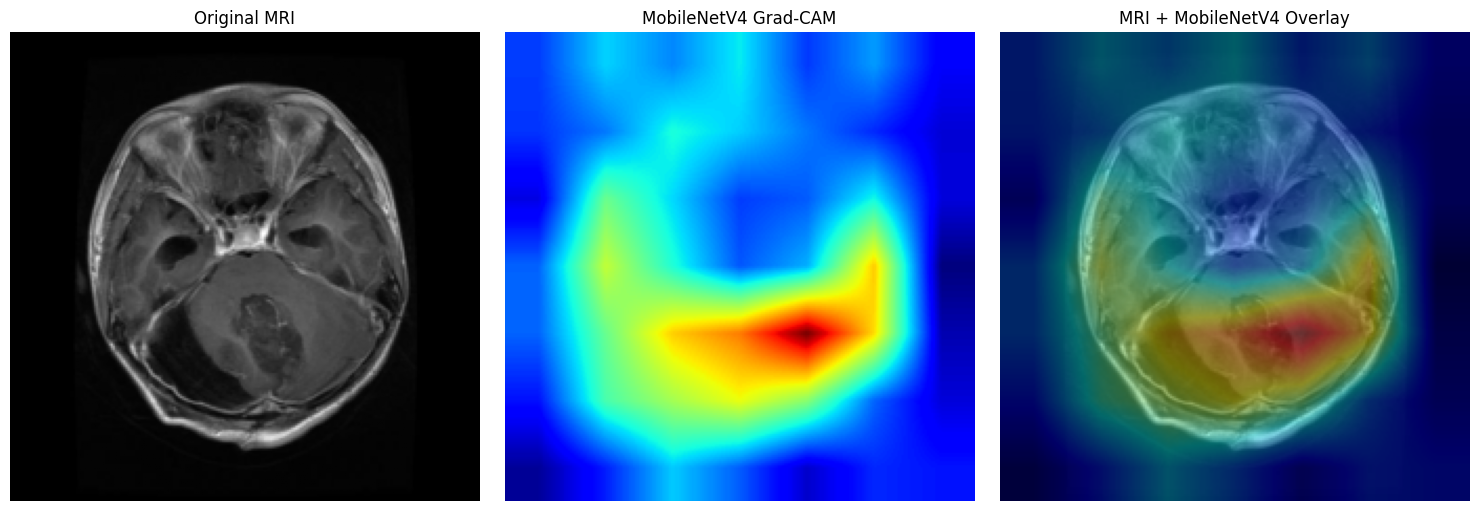

In [ ]:
# Resize heatmap to MRI dimensions
mobilenet_heatmap = cv2.resize(
    mobilenet_cam,
    (original_image.shape[1], original_image.shape[0])
)

# Convert heatmap to color
mobilenet_heatmap_color = cv2.applyColorMap(
    np.uint8(255 * mobilenet_heatmap),
    cv2.COLORMAP_JET
)

mobilenet_heatmap_color = cv2.cvtColor(
    mobilenet_heatmap_color,
    cv2.COLOR_BGR2RGB
)

# Create overlay
mobilenet_overlay = cv2.addWeighted(
    cv2.cvtColor(original_image, cv2.COLOR_GRAY2RGB),
    0.6,
    mobilenet_heatmap_color,
    0.4,
    0
)

# Display
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image, cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mobilenet_heatmap, cmap="jet")
plt.title("MobileNetV4 Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mobilenet_overlay)
plt.title("MRI + MobileNetV4 Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Create a reusable Grad-CAM function

In [ ]:
# Store the three models and their target layers
xai_models = {
    "RepViT": (
        repvit_model,
        repvit_target_layer,
        repvit_class_to_index
    ),
    "ConvNeXt": (
        convnext_model,
        convnext_target_layer,
        convnext_class_to_index
    ),
    "MobileNetV4": (
        mobilenet_model,
        mobilenet_target_layer,
        mobilenet_class_to_index
    )
}

def generate_gradcam(model, target_layer, class_to_index, image_path, true_label):

    captured = {}

    def forward_hook(module, inputs, output):
        captured["activation"] = output
        output.register_hook(
            lambda grad: captured.update({"gradient": grad})
        )

    hook = target_layer.register_forward_hook(forward_hook)

    try:
        with Image.open(image_path) as image:
            gray_image = image.convert("L").resize(
                (224, 224), Image.Resampling.BILINEAR
            )

        x = pil_to_tensor(gray_image).float().div(255)
        x = x.repeat(3, 1, 1)
        x = normalize(x).unsqueeze(0).to(device)

        model.zero_grad(set_to_none=True)

        with torch.enable_grad():
            logits = model(x)
            predicted_index = logits.argmax(dim=1).item()

            target_index = class_to_index[true_label]
            logits[0, target_index].backward()

        activation = captured["activation"]
        gradient = captured["gradient"]

        weights = gradient.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * activation).sum(dim=1))

        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        return (
            cam.squeeze().detach().cpu().numpy(),
            list(class_to_index.keys())[predicted_index]
        )

    finally:
        hook.remove()

print("Grad-CAM function created successfully!")
print("Models ready:", list(xai_models.keys()))

Grad-CAM function created successfully!
Models ready: ['RepViT', 'ConvNeXt', 'MobileNetV4']


Test all three models on one MRI

In [ ]:
first_case = case_selection.iloc[0]

print("Available columns:", case_selection.columns.tolist())
print("\nFirst MRI:", first_case["filename"])
print("MRI path:", first_case["relative_path"])

Available columns: ['manifest_index', 'relative_path', 'true_label', 'RepViT M0.9', 'ConvNeXt V2 Atto', 'MobileNetV4 Conv Small', 'all_correct', 'any_error', 'disagreement', 'case_type', 'filename']

First MRI: brisc2025_test_00001_gl_ax_t1.jpg
MRI path: classification_task\test\glioma\brisc2025_test_00001_gl_ax_t1.jpg


In [ ]:
first_case = case_selection.iloc[0]

image_path = image_root / first_case["relative_path"].replace("\\", "/")
true_label = first_case["true_label"]

test_results = {}

for model_name, (model, target_layer, class_map) in xai_models.items():

    cam, predicted_class = generate_gradcam(
        model,
        target_layer,
        class_map,
        image_path,
        true_label
    )

    test_results[model_name] = cam

    print(f"\nModel: {model_name}")
    print("True class:", true_label)
    print("Predicted class:", predicted_class)
    print("Heatmap shape:", cam.shape)
    print("Heatmap finite:", bool(np.isfinite(cam).all()))

print("\nAll three models tested successfully!")


Model: RepViT
True class: glioma
Predicted class: glioma
Heatmap shape: (7, 7)
Heatmap finite: True

Model: ConvNeXt
True class: glioma
Predicted class: glioma
Heatmap shape: (7, 7)
Heatmap finite: True

Model: MobileNetV4
True class: glioma
Predicted class: glioma
Heatmap shape: (7, 7)
Heatmap finite: True

All three models tested successfully!


In [ ]:
import pandas as pd
from pathlib import Path

gradcam_dir = output_dir / "gradcam_comparison"
gradcam_dir.mkdir(parents=True, exist_ok=True)

gradcam_records = []

for case_number, (_, case) in enumerate(case_selection.iterrows(), start=1):

    image_path = image_root / case["relative_path"].replace("\\", "/")
    true_label = case["true_label"]

    for model_name, (model, target_layer, class_map) in xai_models.items():

        cam, predicted_class = generate_gradcam(
            model,
            target_layer,
            class_map,
            image_path,
            true_label
        )

        filename = f"case_{case_number}_{model_name.lower()}.npy"
        np.save(gradcam_dir / filename, cam)

        gradcam_records.append({
            "case_number": case_number,
            "filename": case["filename"],
            "true_label": true_label,
            "model": model_name,
            "predicted_class": predicted_class,
            "heatmap_file": filename,
            "heatmap_shape": str(cam.shape)
        })

    print(f"Completed case {case_number}/8: {case['filename']}")

gradcam_results = pd.DataFrame(gradcam_records)

csv_path = gradcam_dir / "gradcam_results.csv"
gradcam_results.to_csv(csv_path, index=False)

print("\nTotal heatmaps generated:", len(gradcam_results))
print("Results saved:", csv_path)
print("Heatmap folder:", gradcam_dir)

Completed case 1/8: brisc2025_test_00001_gl_ax_t1.jpg
Completed case 2/8: brisc2025_test_00004_gl_ax_t1.jpg
Completed case 3/8: brisc2025_test_00260_me_ax_t1.jpg
Completed case 4/8: brisc2025_test_00255_me_ax_t1.jpg
Completed case 5/8: brisc2025_test_00561_no_ax_t1.jpg
Completed case 6/8: brisc2025_test_00562_no_ax_t1.jpg
Completed case 7/8: brisc2025_test_00701_pi_ax_t1.jpg
Completed case 8/8: brisc2025_test_00702_pi_ax_t1.jpg

Total heatmaps generated: 24
Results saved: /content/drive/MyDrive/Group8_BRISC_XAI_Work/xai_outputs/gradcam_comparison/gradcam_results.csv
Heatmap folder: /content/drive/MyDrive/Group8_BRISC_XAI_Work/xai_outputs/gradcam_comparison


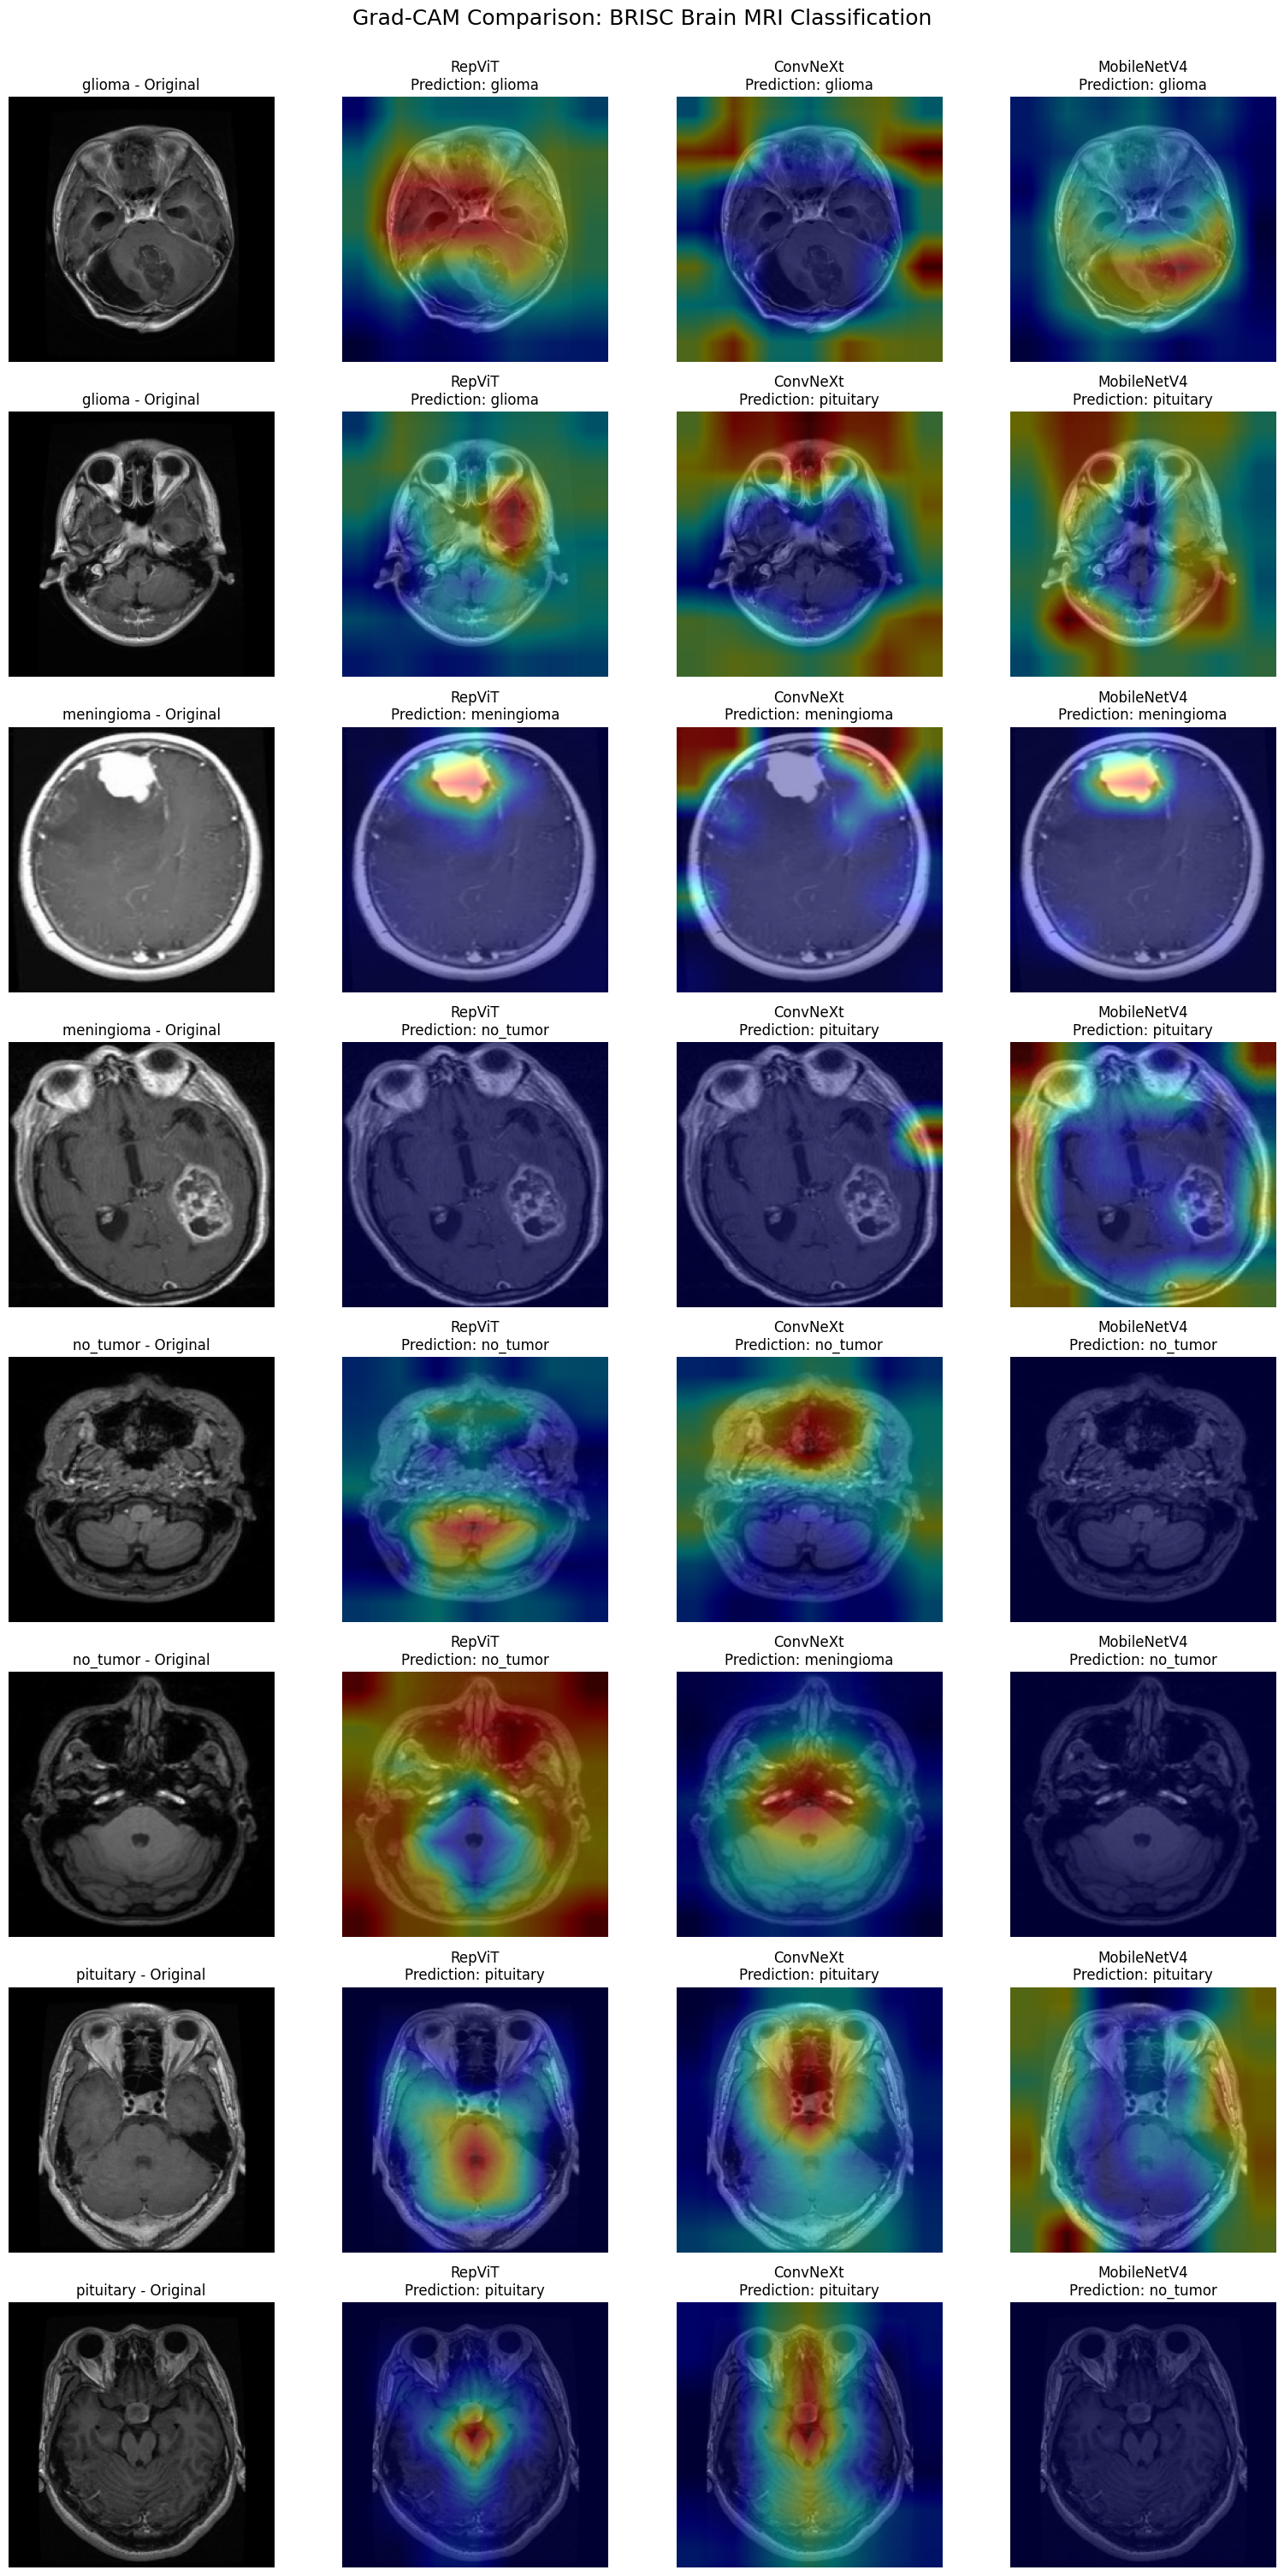

Comparison figure saved: /content/drive/MyDrive/Group8_BRISC_XAI_Work/xai_outputs/gradcam_comparison/all_models_gradcam_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

model_names = ["RepViT", "ConvNeXt", "MobileNetV4"]

fig, axes = plt.subplots(8, 4, figsize=(16, 30))

for i, (_, case) in enumerate(case_selection.iterrows()):

    image_path = image_root / case["relative_path"].replace("\\", "/")

    with Image.open(image_path) as image:
        original = np.array(
            image.convert("L").resize((224, 224))
        )

    axes[i, 0].imshow(original, cmap="gray")
    axes[i, 0].set_title(
        f"{case['true_label']} - Original"
    )

    for j, model_name in enumerate(model_names, start=1):

        heatmap_file = (
            f"case_{i+1}_{model_name.lower()}.npy"
        )

        cam = np.load(gradcam_dir / heatmap_file)

        resized_cam = cv2.resize(cam, (224, 224))

        colored_cam = cv2.applyColorMap(
            np.uint8(255 * resized_cam),
            cv2.COLORMAP_JET
        )

        colored_cam = cv2.cvtColor(
            colored_cam, cv2.COLOR_BGR2RGB
        )

        original_rgb = cv2.cvtColor(
            original, cv2.COLOR_GRAY2RGB
        )

        overlay = cv2.addWeighted(
            original_rgb, 0.6,
            colored_cam, 0.4, 0
        )

        prediction = gradcam_results[
            (gradcam_results["case_number"] == i + 1) &
            (gradcam_results["model"] == model_name)
        ]["predicted_class"].iloc[0]

        axes[i, j].imshow(overlay)
        axes[i, j].set_title(
            f"{model_name}\nPrediction: {prediction}"
        )

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle(
    "Grad-CAM Comparison: BRISC Brain MRI Classification",
    fontsize=18,
    y=1.002
)

plt.tight_layout()

figure_path = gradcam_dir / "all_models_gradcam_comparison.png"

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Comparison figure saved:", figure_path)

In [ ]:
import pandas as pd

comparison_data = {
    "Model": [
        "RepViT M0.9",
        "ConvNeXt V2 Atto",
        "MobileNetV4 Conv Small"
    ],
    "Correct Predictions": [
        970, 963, 882
    ],
    "Incorrect Predictions": [
        30, 37, 118
    ],
    "Accuracy (%)": [
        97.0, 96.3, 88.2
    ]
}

comparison_df = pd.DataFrame(comparison_data)

display(comparison_df)

comparison_path = output_dir / "final_model_comparison.csv"

comparison_df.to_csv(comparison_path, index=False)

print("Comparison table saved:", comparison_path)

,Model,Correct Predictions,Incorrect Predictions,Accuracy (%)
0,RepViT M0.9,970,30,97.0
1,ConvNeXt V2 Atto,963,37,96.3
2,MobileNetV4 Conv Small,882,118,88.2


Comparison table saved: /content/drive/MyDrive/Group8_BRISC_XAI_Work/xai_outputs/final_model_comparison.csv
